# Project 2: House Price Prediction System
** Rajendra Singh Bisht MCA III Semester (Session 2026-2027) - COER University, Roorkee | Lab Sheet-06**

**Problem:** Predict the price of a house (in lakh rupees) from its area, number
of bedrooms, bathrooms, parking spaces, age and location.

**Workflow:** load data -> explore -> clean (duplicates, outliers) -> split ->
preprocessing pipeline -> compare algorithms -> tune the best -> evaluate ->
visualize -> save the model -> predict.

## Step 1: Imports and settings

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()
    if BASE_DIR.name == "notebooks":
        BASE_DIR = BASE_DIR.parent

DATA_PATH = BASE_DIR / "datasets" / "house_prices.csv"
MODEL_DIR = BASE_DIR / "models"
OUT_DIR = BASE_DIR / "outputs"
MODEL_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 200)          # show wide tables fully
pd.set_option("display.max_columns", 20)

RANDOM_STATE = 42
NUMERIC_COLUMNS = ["area_sqft", "bedrooms", "bathrooms", "parking", "age_years"]
CATEGORICAL_COLUMNS = ["location"]
FEATURE_COLUMNS = NUMERIC_COLUMNS + CATEGORICAL_COLUMNS
TARGET = "price_lakh"


def save_and_show(file_name):
    """Save the current figure into the outputs folder and display it."""
    plt.savefig(OUT_DIR / file_name, dpi=120, bbox_inches="tight")
    plt.show()


def iqr_limits(series, factor=1.5):
    """Lower and upper limit of the IQR rule (values outside are outliers)."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    spread = q3 - q1
    return q1 - factor * spread, q3 + factor * spread

## Step 2: Load the dataset

In [2]:
try:
    if not DATA_PATH.exists():
        raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")
    raw_df = pd.read_csv(DATA_PATH)
except (FileNotFoundError, pd.errors.ParserError) as err:
    print("Error while loading dataset:", err)
    raise

print("Shape:", raw_df.shape)
print(raw_df.head())

Shape: (608, 8)
   house_id  area_sqft  bedrooms  bathrooms  parking  age_years      location  price_lakh
0      7001      841.0       1.0        1.0      1.0        8.0  Near Highway        35.7
1      7002     1079.0       1.0        1.0      0.0        9.0      Old Town        67.8
2      7003     1442.0       3.0        3.0      1.0        NaN  Suburb North        68.5
3      7004     1449.0       3.0        3.0      2.0       30.0  Suburb South        71.3
4      7005      944.0       2.0        2.0      0.0       14.0  Suburb South        41.3


## Step 3: Explore the data (EDA)

In [3]:
raw_df.info()
print("\nSummary statistics:\n", raw_df.describe().round(2))
print("\nMissing values:\n", raw_df.isnull().sum())
print("\nDuplicate rows:", raw_df.duplicated().sum())
print("\nHouses per location:\n", raw_df["location"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 608 entries, 0 to 607
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   house_id    608 non-null    int64  
 1   area_sqft   600 non-null    float64
 2   bedrooms    608 non-null    float64
 3   bathrooms   587 non-null    float64
 4   parking     593 non-null    float64
 5   age_years   583 non-null    float64
 6   location    596 non-null    str    
 7   price_lakh  608 non-null    float64
dtypes: float64(6), int64(1), str(1)
memory usage: 44.8 KB

Summary statistics:
        house_id  area_sqft  bedrooms  bathrooms  parking  age_years  price_lakh
count    608.00     600.00    608.00     587.00   593.00     583.00      608.00
mean    7301.37    1332.48      2.45       2.03     0.92      17.44       79.35
std      173.30     731.47      0.96       0.95     0.77      10.46       39.80
min     7001.00     471.00      1.00       1.00     0.00       0.00       13.30
25%     7150.75 

## Step 4: Clean the data
1. Remove duplicate rows.
2. Find **outliers** with the IQR rule (a very large area or price).
3. Remove the *extreme* outliers (beyond 3 x IQR). These few mansions would
   pull the model away from normal houses.

Missing values are filled later inside the pipeline (Step 7), using only the
training data.

In [4]:
clean_df = raw_df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(clean_df))

print("\nOutliers found with the usual IQR rule (1.5 x IQR):")
for column in ["area_sqft", TARGET]:
    low, high = iqr_limits(clean_df[column].dropna())
    count = ((clean_df[column] < low) | (clean_df[column] > high)).sum()
    print(f"  {column}: {count} outliers (limits {low:.0f} to {high:.0f})")

# Remove only the extreme ones (3 x IQR)
keep = pd.Series(True, index=clean_df.index)
for column in ["area_sqft", TARGET]:
    low, high = iqr_limits(clean_df[column].dropna(), factor=3.0)
    keep &= clean_df[column].isna() | clean_df[column].between(low, high)
print(f"\nExtreme outliers removed: {(~keep).sum()}")
before_cleaning_df = clean_df.copy()
clean_df = clean_df[keep].reset_index(drop=True)
print("Rows kept:", len(clean_df))

# Rows without a price cannot be used to train or test a price model
clean_df = clean_df.dropna(subset=[TARGET]).reset_index(drop=True)
print("Rows with a known price:", len(clean_df))

Rows after removing duplicates: 600

Outliers found with the usual IQR rule (1.5 x IQR):
  area_sqft: 19 outliers (limits 236 to 2240)
  price_lakh: 25 outliers (limits -2 to 150)

Extreme outliers removed: 7
Rows kept: 593
Rows with a known price: 593


## Step 5: Visualize the data

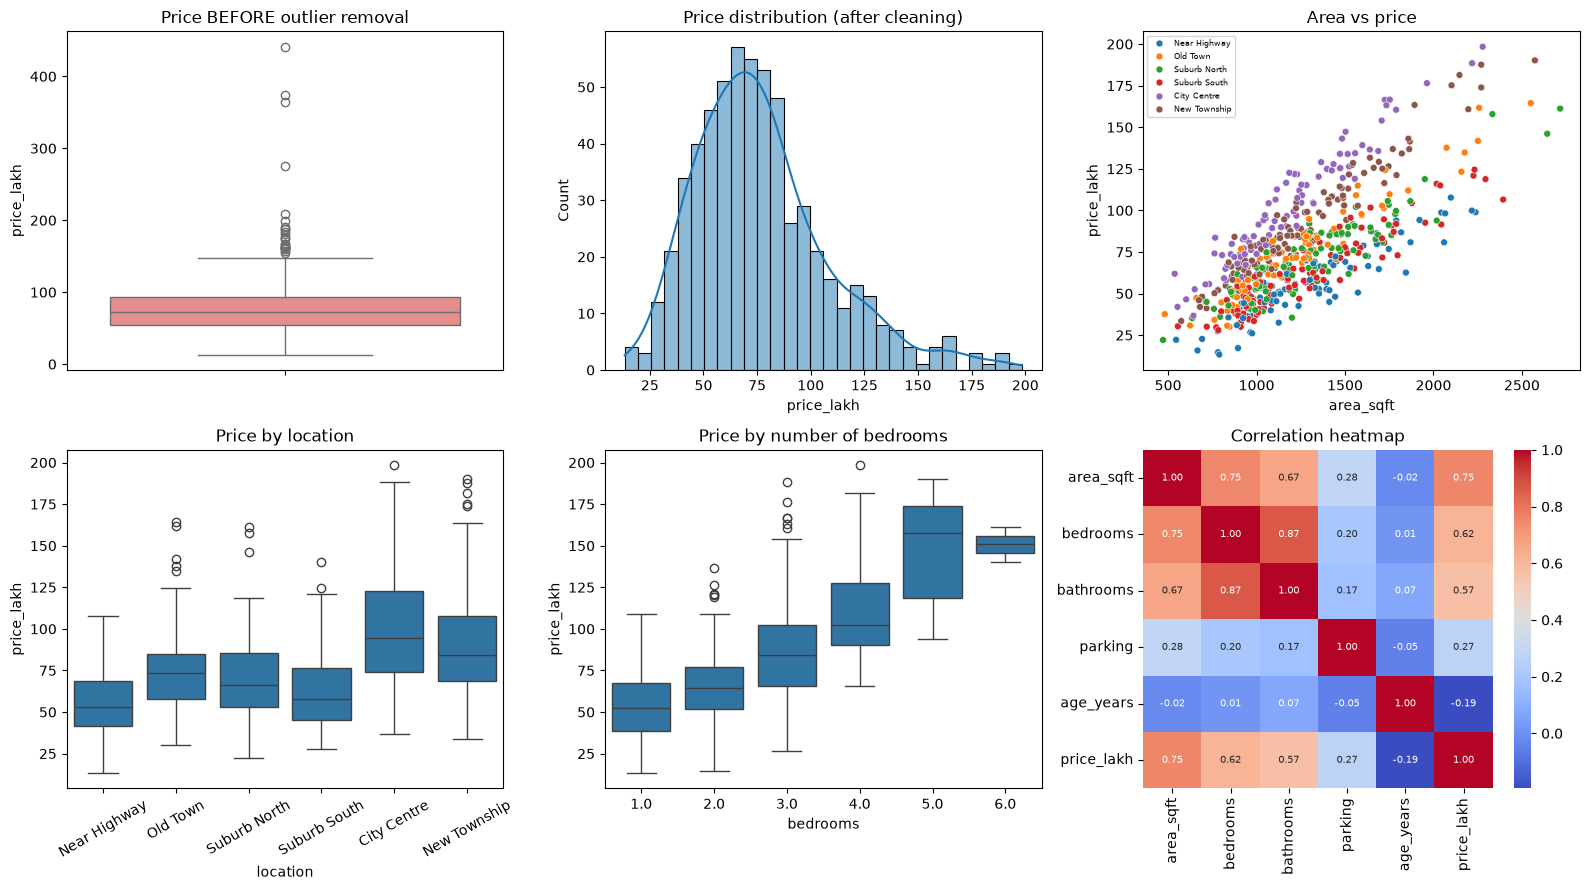

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sns.boxplot(y=before_cleaning_df[TARGET], ax=axes[0, 0], color="lightcoral")
axes[0, 0].set_title("Price BEFORE outlier removal")
sns.histplot(clean_df[TARGET], bins=30, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Price distribution (after cleaning)")
sns.scatterplot(x="area_sqft", y=TARGET, hue="location", data=clean_df, ax=axes[0, 2], s=25)
axes[0, 2].set_title("Area vs price")
axes[0, 2].legend(fontsize=6)
sns.boxplot(x="location", y=TARGET, data=clean_df, ax=axes[1, 0])
axes[1, 0].set_title("Price by location")
axes[1, 0].tick_params(axis="x", rotation=30)
sns.boxplot(x="bedrooms", y=TARGET, data=clean_df, ax=axes[1, 1])
axes[1, 1].set_title("Price by number of bedrooms")
sns.heatmap(clean_df[NUMERIC_COLUMNS + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            ax=axes[1, 2], annot_kws={"size": 7})
axes[1, 2].set_title("Correlation heatmap")
plt.tight_layout()
save_and_show("p2_eda.png")

## Step 6: Split into training and testing sets
80% of the houses train the model and 20% are kept hidden to test it.

In [6]:
X = clean_df[FEATURE_COLUMNS]
y = clean_df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Training houses:", len(X_train), "| Testing houses:", len(X_test))

Training houses: 474 | Testing houses: 119


## Step 7: Preprocessing pipeline
- Numeric columns: fill missing values with the **median**, then **standardize**.
- `location`: fill missing values with the **most common** location, then **one-hot encode**.

In [7]:
numeric_pipeline = Pipeline([("fill_missing", SimpleImputer(strategy="median")),
                             ("scale", StandardScaler())])
categorical_pipeline = Pipeline([("fill_missing", SimpleImputer(strategy="most_frequent")),
                                 ("encode", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("numeric", numeric_pipeline, NUMERIC_COLUMNS),
                                  ("categorical", categorical_pipeline, CATEGORICAL_COLUMNS)])
print(preprocessor)

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('fill_missing',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['area_sqft', 'bedrooms', 'bathrooms',
                                  'parking', 'age_years']),
                                ('categorical',
                                 Pipeline(steps=[('fill_missing',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['location'])])


## Step 8: Compare different regression algorithms

In [8]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

fitted_pipelines, result_rows = {}, []
for name, model in models.items():
    pipeline = Pipeline([("preprocess", preprocessor), ("model", model)])
    pipeline.fit(X_train, y_train)
    test_predictions = pipeline.predict(X_test)
    cv_r2 = cross_val_score(pipeline, X_train, y_train, cv=5, scoring="r2")
    mse = mean_squared_error(y_test, test_predictions)
    fitted_pipelines[name] = pipeline
    result_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, test_predictions),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAPE %": mean_absolute_percentage_error(y_test, test_predictions) * 100,
        "R2 (train)": r2_score(y_train, pipeline.predict(X_train)),
        "R2 (test)": r2_score(y_test, test_predictions),
        "R2 (5-fold CV)": cv_r2.mean(),
    })

results_table = pd.DataFrame(result_rows).set_index("Model").round(4)
print(results_table.sort_values("R2 (test)", ascending=False))

                      MAE       MSE     RMSE   MAPE %  R2 (train)  R2 (test)  R2 (5-fold CV)
Model                                                                                       
Ridge Regression   6.4831   80.5588   8.9755   9.9857      0.9102     0.8585          0.9034
Linear Regression  6.4997   80.7809   8.9878  10.0418      0.9103     0.8581          0.9034
Gradient Boosting  6.8477   87.4765   9.3529  10.3455      0.9694     0.8464          0.9092
Random Forest      7.6113   99.6994   9.9850  11.7065      0.9849     0.8249          0.8862
Decision Tree      9.1809  139.2511  11.8005  14.2605      0.9190     0.7554          0.7953


## Step 9: Interpret the results
- **MAE / RMSE** are in *lakh rupees*: the typical mistake of the model.
- **MAPE** is the mistake as a percentage of the real price.
- **R2** is the share of the price differences the model explains.
- If **R2 (train)** is much higher than **R2 (test)**, the model is *overfitting*
  (it memorized the training houses).

In [9]:
best_name = results_table["R2 (test)"].idxmax()
best_row = results_table.loc[best_name]
print(f"Best model so far: {best_name}")
print(f"- Predictions are about {best_row['MAE']:.1f} lakh away from the real price on average (MAE).")
print(f"- The typical error (RMSE) is {best_row['RMSE']:.1f} lakh, about {best_row['MAPE %']:.1f}% of the price.")
print(f"- R2 = {best_row['R2 (test)']:.3f}: the model explains {best_row['R2 (test)'] * 100:.1f}% of the price differences.")
gap = best_row["R2 (train)"] - best_row["R2 (test)"]
print(f"- Train R2 minus test R2 = {gap:.3f} -> {'possible overfitting' if gap > 0.1 else 'no strong overfitting'}.")

Best model so far: Ridge Regression
- Predictions are about 6.5 lakh away from the real price on average (MAE).
- The typical error (RMSE) is 9.0 lakh, about 10.0% of the price.
- R2 = 0.859: the model explains 85.9% of the price differences.
- Train R2 minus test R2 = 0.052 -> no strong overfitting.


## Step 10: Tune the best tree-based model (Hyperparameter tuning)
We try several settings of Gradient Boosting with 3-fold cross-validation and
keep the best combination.

In [10]:
tuning_pipeline = Pipeline([("preprocess", preprocessor),
                            ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))])
parameter_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [2, 3, 4],
    "model__learning_rate": [0.05, 0.1],
}
grid_search = GridSearchCV(tuning_pipeline, parameter_grid, cv=3, scoring="r2", n_jobs=1)
grid_search.fit(X_train, y_train)
print("Best settings:", grid_search.best_params_)
print("Best CV R2   :", round(grid_search.best_score_, 4))

tuned_predictions = grid_search.best_estimator_.predict(X_test)
tuned_mse = mean_squared_error(y_test, tuned_predictions)
tuned_row = {
    "MAE": mean_absolute_error(y_test, tuned_predictions), "MSE": tuned_mse,
    "RMSE": np.sqrt(tuned_mse),
    "MAPE %": mean_absolute_percentage_error(y_test, tuned_predictions) * 100,
    "R2 (train)": r2_score(y_train, grid_search.best_estimator_.predict(X_train)),
    "R2 (test)": r2_score(y_test, tuned_predictions), "R2 (5-fold CV)": grid_search.best_score_,
}
fitted_pipelines["Gradient Boosting (tuned)"] = grid_search.best_estimator_
results_table.loc["Gradient Boosting (tuned)"] = pd.Series(tuned_row).round(4)
print("\nAll models:")
print(results_table.sort_values("R2 (test)", ascending=False))

best_name = results_table["R2 (test)"].idxmax()
best_pipeline = fitted_pipelines[best_name]
print("\nFinal best model:", best_name)

Best settings: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200}
Best CV R2   : 0.9077

All models:
                              MAE       MSE     RMSE   MAPE %  R2 (train)  R2 (test)  R2 (5-fold CV)
Model                                                                                               
Ridge Regression           6.4831   80.5588   8.9755   9.9857      0.9102     0.8585          0.9034
Linear Regression          6.4997   80.7809   8.9878  10.0418      0.9103     0.8581          0.9034
Gradient Boosting          6.8477   87.4765   9.3529  10.3455      0.9694     0.8464          0.9092
Gradient Boosting (tuned)  6.6595   87.6927   9.3644  10.1075      0.9628     0.8460          0.9077
Random Forest              7.6113   99.6994   9.9850  11.7065      0.9849     0.8249          0.8862
Decision Tree              9.1809  139.2511  11.8005  14.2605      0.9190     0.7554          0.7953

Final best model: Ridge Regression


## Step 11: Visualize the results

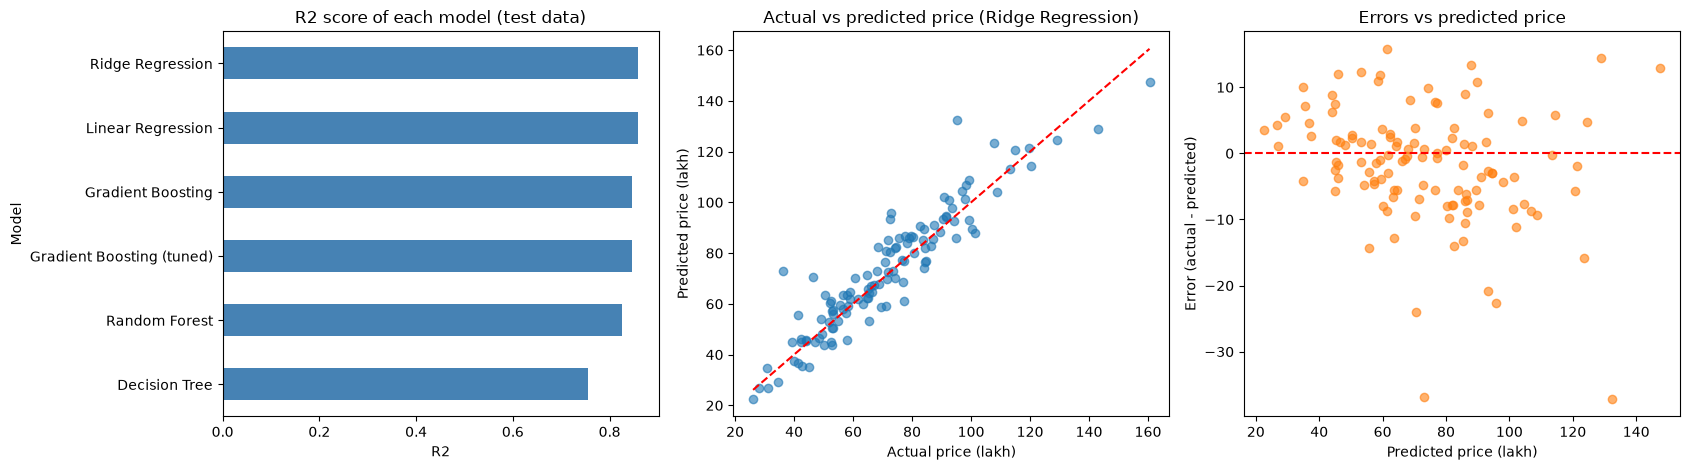

In [11]:
best_predictions = best_pipeline.predict(X_test)
residuals = y_test - best_predictions

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
results_table["R2 (test)"].sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("R2 score of each model (test data)")
axes[0].set_xlabel("R2")

axes[1].scatter(y_test, best_predictions, alpha=0.6)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[1].set_title(f"Actual vs predicted price ({best_name})")
axes[1].set_xlabel("Actual price (lakh)")
axes[1].set_ylabel("Predicted price (lakh)")

axes[2].scatter(best_predictions, residuals, alpha=0.6, color="tab:orange")
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_title("Errors vs predicted price")
axes[2].set_xlabel("Predicted price (lakh)")
axes[2].set_ylabel("Error (actual - predicted)")
plt.tight_layout()
save_and_show("p2_model_results.png")

## Step 12: Which features matter most?

area_sqft    0.9323
location     0.8931
age_years    0.0766
parking      0.0219
bathrooms    0.0153
bedrooms     0.0079
dtype: float64


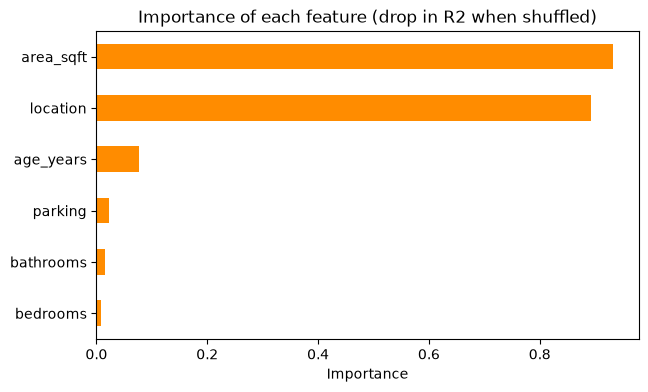

In [12]:
importance = permutation_importance(best_pipeline, X_test, y_test, n_repeats=15,
                                    random_state=RANDOM_STATE, scoring="r2")
importance_series = pd.Series(importance.importances_mean, index=FEATURE_COLUMNS).sort_values()
print(importance_series.sort_values(ascending=False).round(4))

plt.figure(figsize=(7, 4))
importance_series.plot.barh(color="darkorange")
plt.title("Importance of each feature (drop in R2 when shuffled)")
plt.xlabel("Importance")
save_and_show("p2_feature_importance.png")

## Step 13: Save the trained model

In [13]:
try:
    joblib.dump(best_pipeline, MODEL_DIR / "house_price_model.joblib")
    model_info = {
        "model": best_name,
        "metrics": results_table.loc[best_name].to_dict(),
        "feature_columns": FEATURE_COLUMNS,
        "locations": sorted(clean_df["location"].dropna().unique().tolist()),
    }
    with open(MODEL_DIR / "model_info.json", "w", encoding="utf-8") as info_file:
        json.dump(model_info, info_file, indent=2)
    print("Saved in the models folder:")
    for saved_file in sorted(MODEL_DIR.glob("*")):
        print(" -", saved_file.name)
except OSError as err:
    print("Could not save model:", err)

Saved in the models folder:
 - .gitkeep
 - house_price_model.joblib
 - model_info.json


## Step 14: Load the saved model and predict new house prices

In [14]:
loaded_model = joblib.load(MODEL_DIR / "house_price_model.joblib")
new_houses = pd.DataFrame({
    "area_sqft": [900, 1200, 2400],
    "bedrooms": [2, 3, 4],
    "bathrooms": [1, 2, 3],
    "parking": [0, 1, 2],
    "age_years": [15, 8, 2],
    "location": ["Near Highway", "Suburb North", "City Centre"],
})
result = new_houses.copy()
result["Predicted price (lakh)"] = loaded_model.predict(new_houses).round(1)
print(result.to_string(index=False))

 area_sqft  bedrooms  bathrooms  parking  age_years     location  Predicted price (lakh)
       900         2          1        0         15 Near Highway                    27.3
      1200         3          2        1          8 Suburb North                    70.5
      2400         4          3        2          2  City Centre                   188.7


## Conclusion
Several regression algorithms were compared and the best one was tuned. The final
model was evaluated with MAE, RMSE, MAPE and R2, saved with Joblib, and used to
predict the price of new houses. Location and area are the most important features.